# 순환 신경망으로 IMDB 리뷰 분류하기

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/9-2.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
import keras

keras.utils.set_random_seed(42)

## IMDB 리뷰 데이터셋

In [3]:
(train_input, train_target), (test_input, test_target) = keras.datasets.imdb.load_data(num_words=200)
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(25000,) (25000,)
(25000,) (25000,)


In [4]:
print([len(x) for x in train_input[:20]])
print(train_target[:20])

[218, 189, 141, 550, 147, 43, 123, 562, 233, 130, 450, 99, 117, 238, 109, 129, 163, 752, 212, 177]
[1 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 1]


In [5]:
print(len(train_input[0]))
print(train_input[0])

print(len(train_input[1]))
print(train_input[1])

218
[1, 14, 22, 16, 43, 2, 2, 2, 2, 65, 2, 2, 66, 2, 4, 173, 36, 2, 5, 25, 100, 43, 2, 112, 50, 2, 2, 9, 35, 2, 2, 5, 150, 4, 172, 112, 167, 2, 2, 2, 39, 4, 172, 2, 2, 17, 2, 38, 13, 2, 4, 192, 50, 16, 6, 147, 2, 19, 14, 22, 4, 2, 2, 2, 4, 22, 71, 87, 12, 16, 43, 2, 38, 76, 15, 13, 2, 4, 22, 17, 2, 17, 12, 16, 2, 18, 2, 5, 62, 2, 12, 8, 2, 8, 106, 5, 4, 2, 2, 16, 2, 66, 2, 33, 4, 130, 12, 16, 38, 2, 5, 25, 124, 51, 36, 135, 48, 25, 2, 33, 6, 22, 12, 2, 28, 77, 52, 5, 14, 2, 16, 82, 2, 8, 4, 107, 117, 2, 15, 2, 4, 2, 7, 2, 5, 2, 36, 71, 43, 2, 2, 26, 2, 2, 46, 7, 4, 2, 2, 13, 104, 88, 4, 2, 15, 2, 98, 32, 2, 56, 26, 141, 6, 194, 2, 18, 4, 2, 22, 21, 134, 2, 26, 2, 5, 144, 30, 2, 18, 51, 36, 28, 2, 92, 25, 104, 4, 2, 65, 16, 38, 2, 88, 12, 16, 2, 5, 16, 2, 113, 103, 32, 15, 16, 2, 19, 178, 32]
189
[1, 194, 2, 194, 2, 78, 2, 5, 6, 2, 2, 2, 134, 26, 4, 2, 8, 118, 2, 14, 2, 20, 13, 119, 2, 189, 102, 5, 2, 110, 2, 21, 14, 69, 188, 8, 30, 23, 7, 4, 2, 126, 93, 4, 114, 9, 2, 2, 5, 2, 4, 116, 9

In [6]:
train_input, val_input, train_target, val_target = train_test_split(
    train_input, train_target, test_size=0.2, random_state=42
)
print(train_input.shape, train_target.shape)
print(val_input.shape, val_target.shape)

(20000,) (20000,)
(5000,) (5000,)


In [7]:
lengths = np.array([len(x) for x in train_input])
print(np.mean(lengths))
print(np.median(lengths))

239.00925
178.0


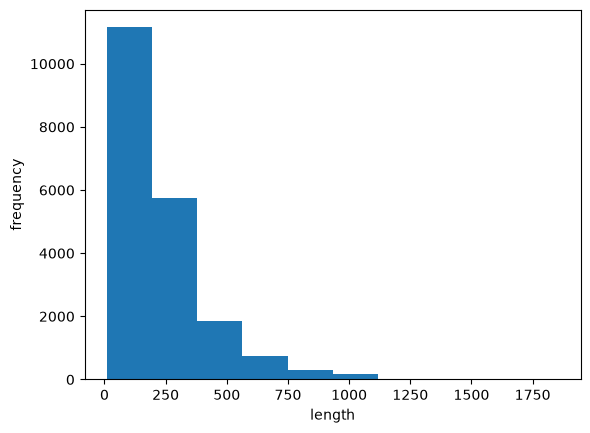

In [9]:
plt.hist(lengths)
plt.xlabel('length')
plt.ylabel('frequency')
plt.show()

In [11]:
train_seq = keras.preprocessing.sequence.pad_sequences(train_input, maxlen=100)     # padding='pre'
print(train_seq.shape)
print(train_seq[0])
print(train_seq[0][-10:])

(20000, 100)
[ 10   4  20   9   2   2   2   5  45   6   2   2  33   2   8   2 142   2
   5   2  17  73  17   2   5   2  19  55   2   2  92  66 104  14  20  93
  76   2 151  33   4  58  12 188   2 151  12   2  69   2 142  73   2   6
   2   7   2   2 188   2 103  14  31  10  10   2   7   2   5   2  80  91
   2  30   2  34  14  20 151  50  26 131  49   2  84  46  50  37  80  79
   6   2  46   7  14  20  10  10   2 158]
[  6   2  46   7  14  20  10  10   2 158]


In [16]:
print([len(x) for x in train_input[:20]])
print(train_seq[5])
print(train_seq[11])

[259, 520, 290, 109, 559, 96, 130, 935, 383, 716, 195, 55, 122, 142, 104, 109, 179, 777, 368, 311]
[  0   0   0   0   1   2 195  19  49   2   2 190   4   2   2   2 183  10
  10  13  82  79   4   2  36  71   2   8   2  25  19  49   7   4   2   2
   2   2   2  10  10  48  25  40   2  11   2   2  40   2   2   5   4   2
   2  95  14   2  56 129   2  10  10  21   2  94   2   2   2   2  11 190
  24   2   2   7  94   2   2  10  10  87   2  34  49   2   7   2   2   2
   2   2   2   2  46  48  64  18   4   2]
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   1  14  16   4  64  58  13 126   2
  46  23   6  20 153   2  13   2  12  11   4   2   2   5 197   2  13 144
   2  12 160   2   2   8 135  15  13  16   2   4  86  58  14   2   2  64
   8   2   2  17   4   2  20   2 126 110]


In [15]:
val_seq = keras.preprocessing.sequence.pad_sequences(val_input, maxlen=100)     # padding='pre'
print(val_seq.shape)
print(val_seq[0])
print(val_seq[0][-10:])

(5000, 100)
[ 32   2   2   6   2   2   2   4   2   2   7  14  22  15 100  28   2  11
   4   2   7   6   2   2   2   2  51  75 130  56  19   9   2   2 105   2
   2   2 186   8  30   8 168   2  33   4   2   8  97   4   2   2  53   2
   6   2   2  38   2   2  17   8   2   4   2   2  46   4   2   5   2   2
   2  15   2 117  53  74  11  31   2  35  23   2   2  34 167   2  14   9
   2  22   2  11   2   2   2  14  58   2]
[ 2 22  2 11  2  2  2 14 58  2]


In [20]:
print([len(x) for x in val_input[:20]])
print(val_seq[2])
print(val_seq[9])

[201, 326, 84, 205, 133, 363, 191, 131, 166, 90, 130, 85, 164, 174, 130, 127, 255, 286, 180, 130]
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1   4
 105  26   2   5   2  19   2 112   2   2   2   2  42   2   2   4 116   9
  99   2  18  12   8  30  78  11  35   2 120   4   2  96  45   2   2  48
   2   6   2   2   2  88  41 109   9  24   6   2   2   2   2   2 109  59
  43   2   8   2   2   6 176  10  10  23   4   2   2  61   2   2  13   2
   4  20   8  30   2   2  42   2  33  32]
[  0   0   0   0   0   0   0   0   0   0   1  14   9   4   2   7  22  18
   6   2   2   2  54   4   2   7   4 182  70 140   2  19  94   2   2  17
  25   2  83   6 194   2   2   5   2  18   6   2   7   2   2   2  39   2
   5   2   2  17   2   2   2   4 114   2  50  26  57   2   8   2  57   2
   2  43   6   2   5   2   2 143 162   2 113  33  94 118   6   2  22  11
 175   2   5  31  15   2   4   2  12   2]


## 순환 신경망 만들기

In [ ]:
model = keras.Sequential()
model.add(keras.layers.Input(shape=(100, 200)))
model.add(keras.layers.SimpleRNN(8))                    # 1,672 = 200 * 8 + 8 * 8 + 8
model.add(keras.layers.Dense(1, activation='sigmoid'))  # 9 = 8 * 1 + 1
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 8)              │         1,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,681 (6.57 KB)

 Trainable params: 1,681 (6.57 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
train_onehot = keras.utils.to_categorical(train_seq)
print(train_onehot.shape)

(20000, 100, 200)


In [27]:
train_onehot[19999][99]  # 어딘가에 1이 하나 있다

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [28]:
val_onehot = keras.utils.to_categorical(val_seq)
print(val_onehot.shape)
print(np.sum(val_onehot[4999][99]))

(5000, 100, 200)
1.0


## 순환 신경망 훈련하기

In [29]:
rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])

best_simplernn_model_path = './best-simplernn-model.keras'
checkpoint_cb = keras.callbacks.ModelCheckpoint(best_simplernn_model_path, save_best_only=True)
early_stopping_cb = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(train_onehot, train_target, epochs=100, batch_size=64,
                    validation_data=(val_onehot, val_target),
                    callbacks=[checkpoint_cb, early_stopping_cb])
print(early_stopping_cb.stopped_epoch)

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4960 - loss: 0.7107 - val_accuracy: 0.4924 - val_loss: 0.7053
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5022 - loss: 0.7027 - val_accuracy: 0.4960 - val_loss: 0.7010
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5068 - loss: 0.6988 - val_accuracy: 0.4962 - val_loss: 0.6984
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5126 - loss: 0.6961 - val_accuracy: 0.5038 - val_loss: 0.6962
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5167 - loss: 0.6940 - val_accuracy: 0.5110 - val_loss: 0.6939
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5221 - loss: 0.6922 - val_accuracy: 0.5120 - val_loss: 0.6925
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5282 - loss: 0.6911 - val_accuracy: 0.5162 - val_loss: 0.6917
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5307 - loss: 0.6902 - val_accu

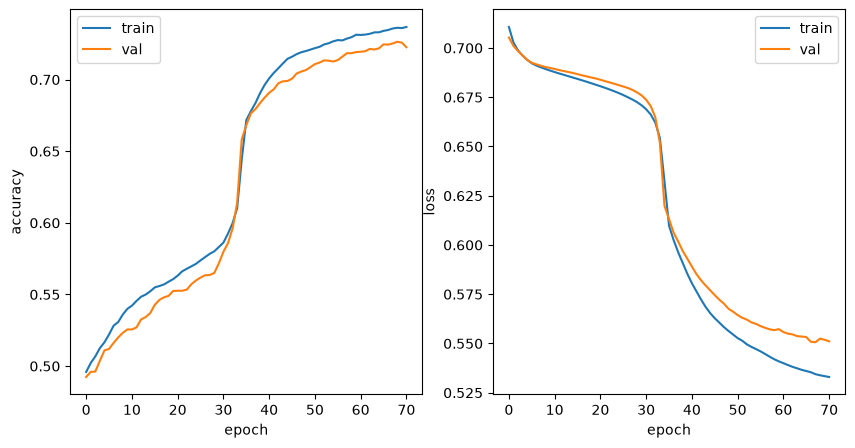

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].plot(history.history['accuracy'])
axes[0].plot(history.history['val_accuracy'])
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('accuracy')
axes[0].legend(['train', 'val'])

axes[1].plot(history.history['loss'])
axes[1].plot(history.history['val_loss'])
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].legend(['train', 'val'])

plt.show()

## 단어 임베딩을 사용하기

In [ ]:
model_embedding = keras.Sequential()
model_embedding.add(keras.layers.Input(shape=(100, )))              # onehot(x) -> seq(o)
model_embedding.add(keras.layers.Embedding(200, 16))                # 3,200 = 200 * 16
model_embedding.add(keras.layers.SimpleRNN(8))                      # 200 = 16 * 8 + 8 * 8 + 8
model_embedding.add(keras.layers.Dense(1, activation='sigmoid'))    # 9 = 8 * 1 + 1
model_embedding.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 16)        │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 8)              │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,409 (13.32 KB)

 Trainable params: 3,409 (13.32 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)
model_embedding.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])

best_embedding_model_path = './best-embedding-model.keras'
checkpoint_cb = keras.callbacks.ModelCheckpoint(best_embedding_model_path, save_best_only=True)
early_stopping_cb = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

history = model_embedding.fit(train_seq, train_target, epochs=100, batch_size=64,
                              validation_data=(val_seq, val_target),
                              callbacks=[checkpoint_cb, early_stopping_cb])
print(early_stopping_cb.stopped_epoch)

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5120 - loss: 0.6928 - val_accuracy: 0.5402 - val_loss: 0.6893
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5881 - loss: 0.6833 - val_accuracy: 0.6090 - val_loss: 0.6802
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6464 - loss: 0.6710 - val_accuracy: 0.6428 - val_loss: 0.6692
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6756 - loss: 0.6567 - val_accuracy: 0.6820 - val_loss: 0.6516
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6880 - loss: 0.6425 - val_accuracy: 0.6910 - val_loss: 0.6373
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6977 - loss: 0.6273 - val_accuracy: 0.6908 - val_loss: 0.6238
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7063 - loss: 0.6112 - val_accuracy: 0.6990 - val_loss: 0.6087
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7118 - loss: 0.5967 - val_accu

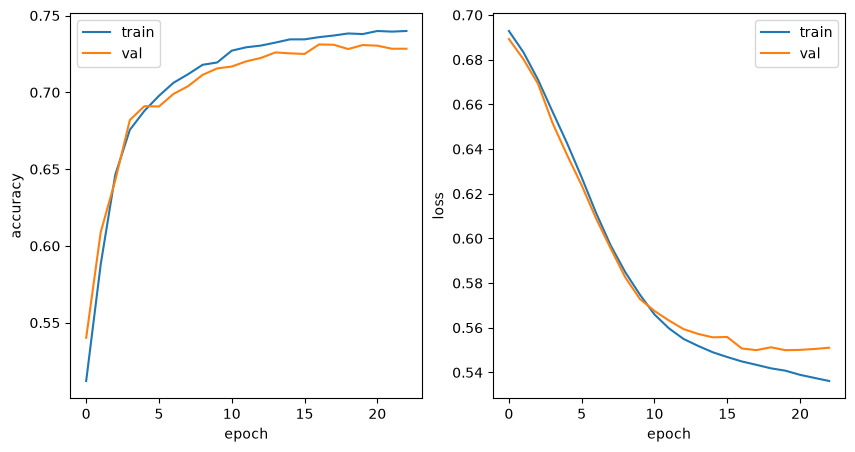

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].plot(history.history['accuracy'])
axes[0].plot(history.history['val_accuracy'])
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('accuracy')
axes[0].legend(['train', 'val'])

axes[1].plot(history.history['loss'])
axes[1].plot(history.history['val_loss'])
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].legend(['train', 'val'])

plt.show()